# Tarea 03
### Aplicar K-NN a todas las parejas de variables del dataset Titanic

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import re
from sklearn import datasets
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [2]:
# 1. Cargar datos
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"
df = pd.read_csv(url)

In [3]:
del df["PassengerId"]
del df["Ticket"]
del df["Cabin"]

In [4]:
title = []
for row in df["Name"]:
    pattern = r", ([A-Za-z ]+\.).*"
    title.append(re.search(pattern, row).group(1))
df["Title"] = title
del df["Name"]

In [5]:
# Imputación
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [6]:
# Feature engineering (Free_ticket se calcula antes de escalar Fare)
df["Family_size"] = df["SibSp"] + df["Parch"] + 1
df["Alone"] = (df["Family_size"] == 1).astype(int)
df["Free_ticket"] = (df["Fare"] == 0).astype(int)

In [7]:
frecuentes = ["Mr.", "Mrs.", "Miss.", "Master."]
df["Title"] = df["Title"].where(df["Title"].isin(frecuentes), "Other")

In [8]:
# Categóricas
df = pd.get_dummies(df, columns=["Pclass", "Sex", "Embarked", "Title"], dtype=int)

In [9]:
# Escalar numéricas
num_cols = ["Age", "SibSp", "Parch", "Fare", "Family_size"]
df[num_cols] = StandardScaler().fit_transform(df[num_cols])

In [10]:
# Separar variables
X = df.drop(columns="Survived")
y = df["Survived"]

In [11]:
print(X.shape, y.shape)

(891, 20) (891,)


In [12]:
from itertools import combinations
from sklearn.pipeline import make_pipeline

def grupo_a_codigo(D, prefijo):
    cols = [c for c in D.columns if c.startswith(prefijo + "_")]
    assert (D[cols].sum(axis=1) == 1).all(), f"{prefijo}: hay filas sin categoría"
    return D[cols].values.argmax(axis=1)

# Una columna por variable original
B = pd.DataFrame({
    "Age": X["Age"].values,
    "SibSp": X["SibSp"].values,
    "Parch": X["Parch"].values,
    "Fare": X["Fare"].values,
    "Family_size": X["Family_size"].values,
    "Alone": X["Alone"].values,
    "Free_ticket": X["Free_ticket"].values,
    "Pclass": grupo_a_codigo(X, "Pclass"),
    "Sex": grupo_a_codigo(X, "Sex"),
    "Embarked": grupo_a_codigo(X, "Embarked"),
    "Title": grupo_a_codigo(X, "Title"),
})

In [17]:
def dibujar_par(ax, a, b):
    X2 = B[[a, b]].values
    modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_vecinos))
    modelo.fit(X2, y.values)
    acc = modelo.score(X2, y.values)

    x_min, x_max = X2[:, 0].min(), X2[:, 0].max() + 1
    y_min, y_max = X2[:, 1].min(), X2[:, 1].max() + 1
    paso_x = (x_max - x_min) / 300
    paso_y = (y_max - y_min) / 300
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, paso_x),
        np.arange(y_min, y_max, paso_y)
    )
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    # #DA1884 No sobrevivió #4169E1 Sovrevivió
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5],
                cmap=ListedColormap(["#DA1884", "#4169E1"]), alpha=0.6)

    rng = np.random.default_rng(0)
    jx = X2[:, 0] + rng.uniform(-0.08, 0.08, len(X2))
    jy = X2[:, 1] + rng.uniform(-0.08, 0.08, len(X2))
    sns.scatterplot(
        x=jx, y=jy,
        hue=y.map({0: "No sobrevivió", 1: "Sobrevivió"}).values,
        palette=["pink", "blue"],
        alpha=1.0, edgecolor="black", s=20, ax=ax,
    )

    ax.set_title(f"{a} vs {b}  (acc train = {acc:.2f})", fontsize=10)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.legend(title="Clase", fontsize=7)
    return acc

Total de pares: 55


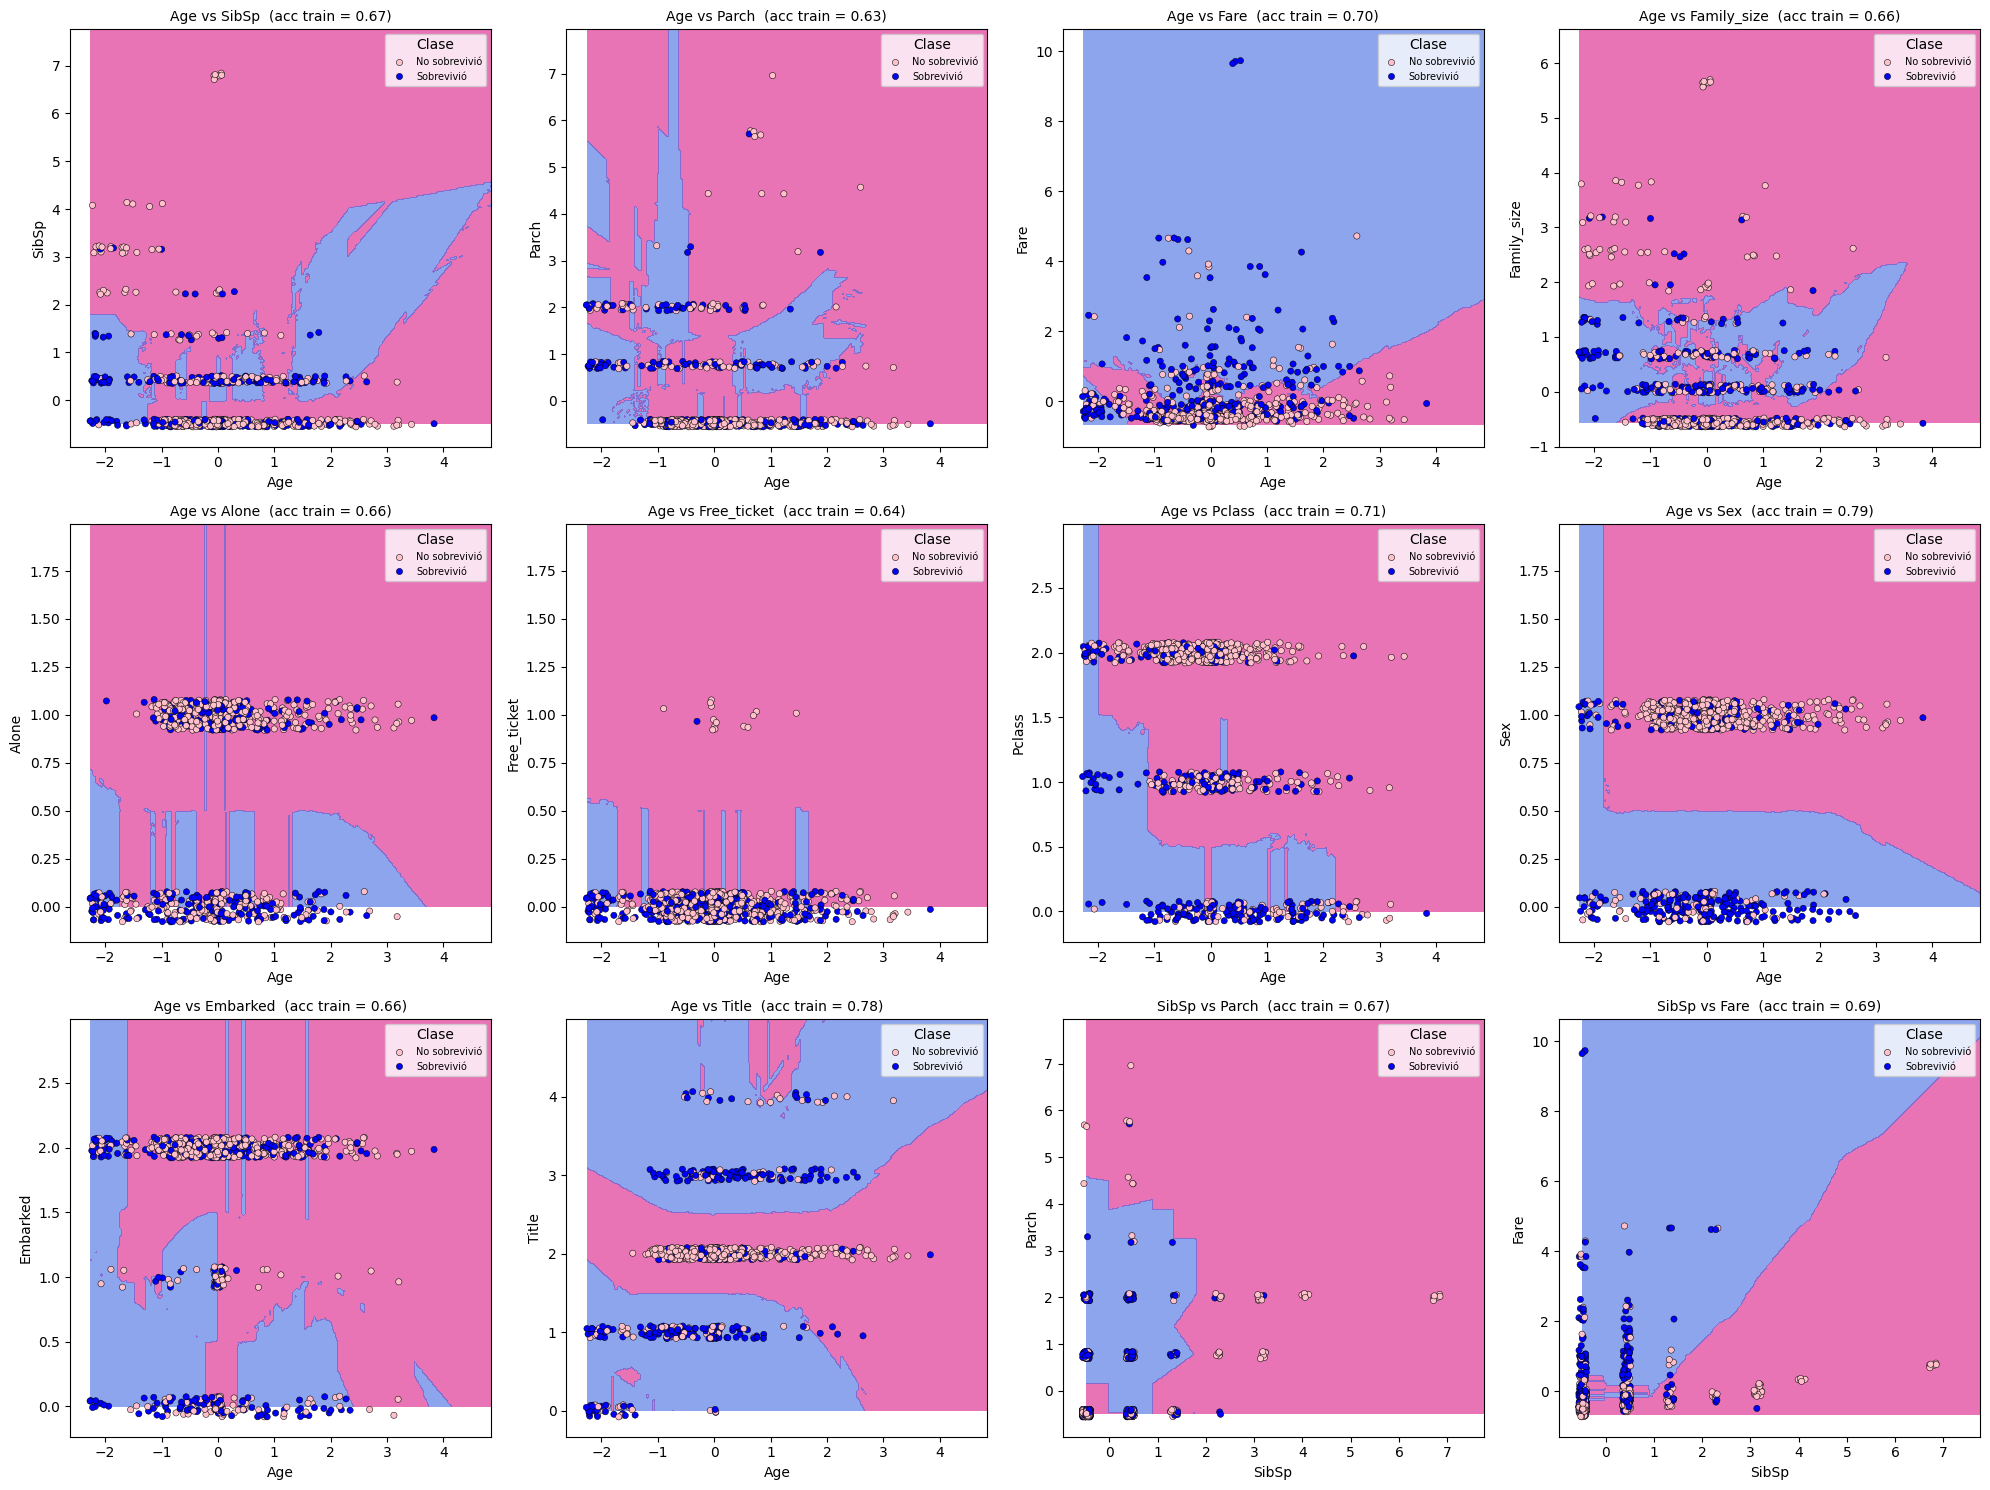

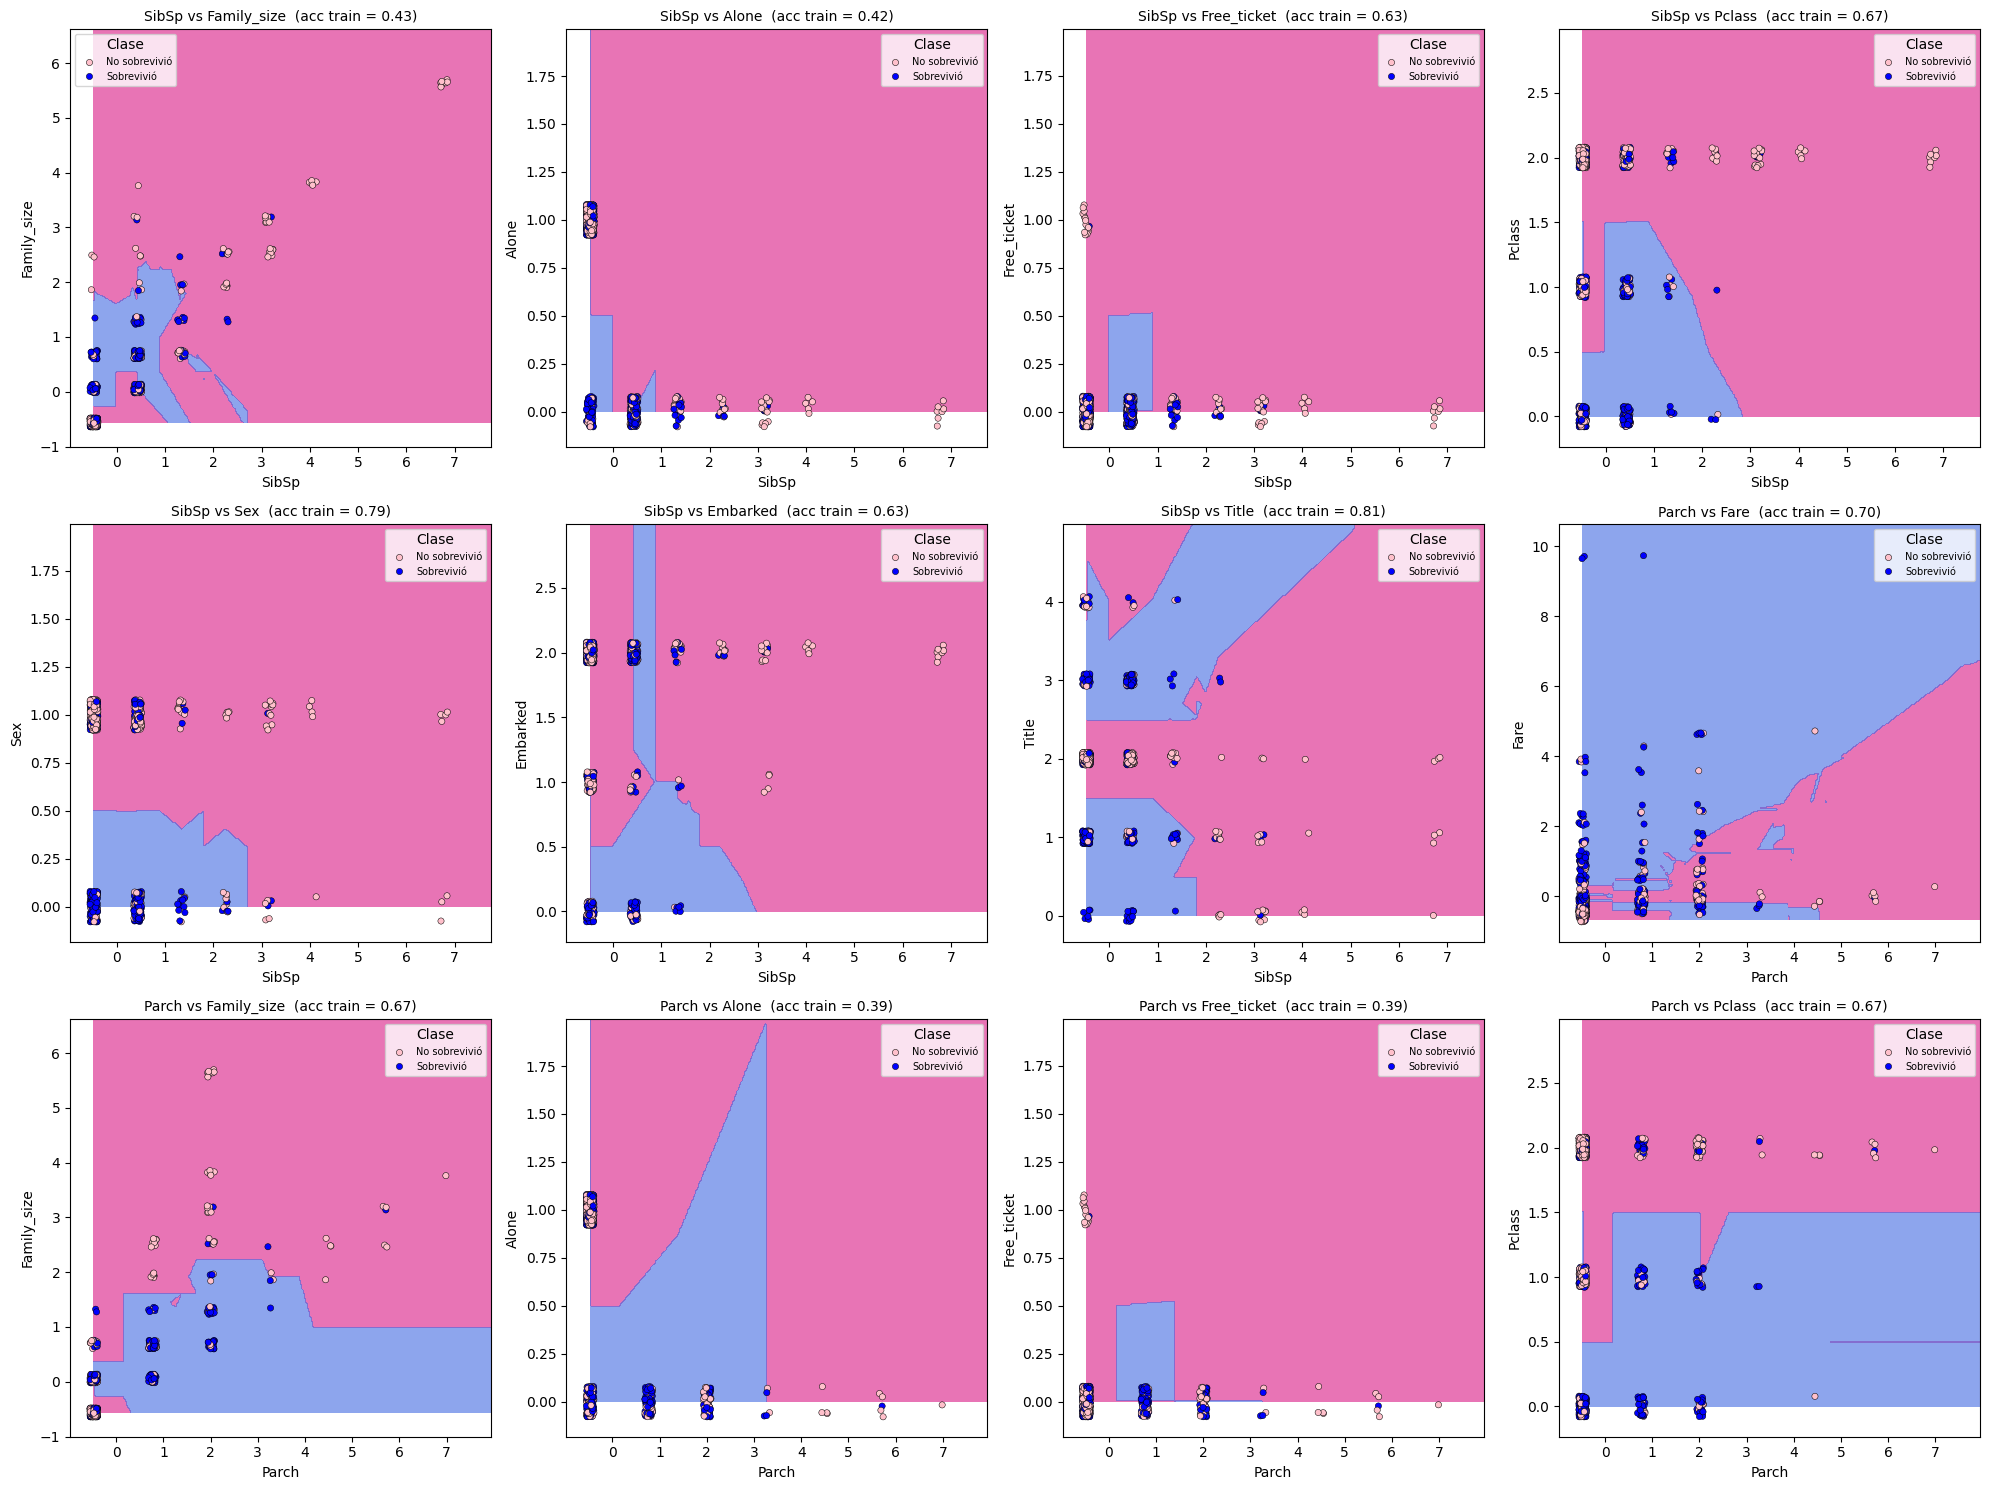

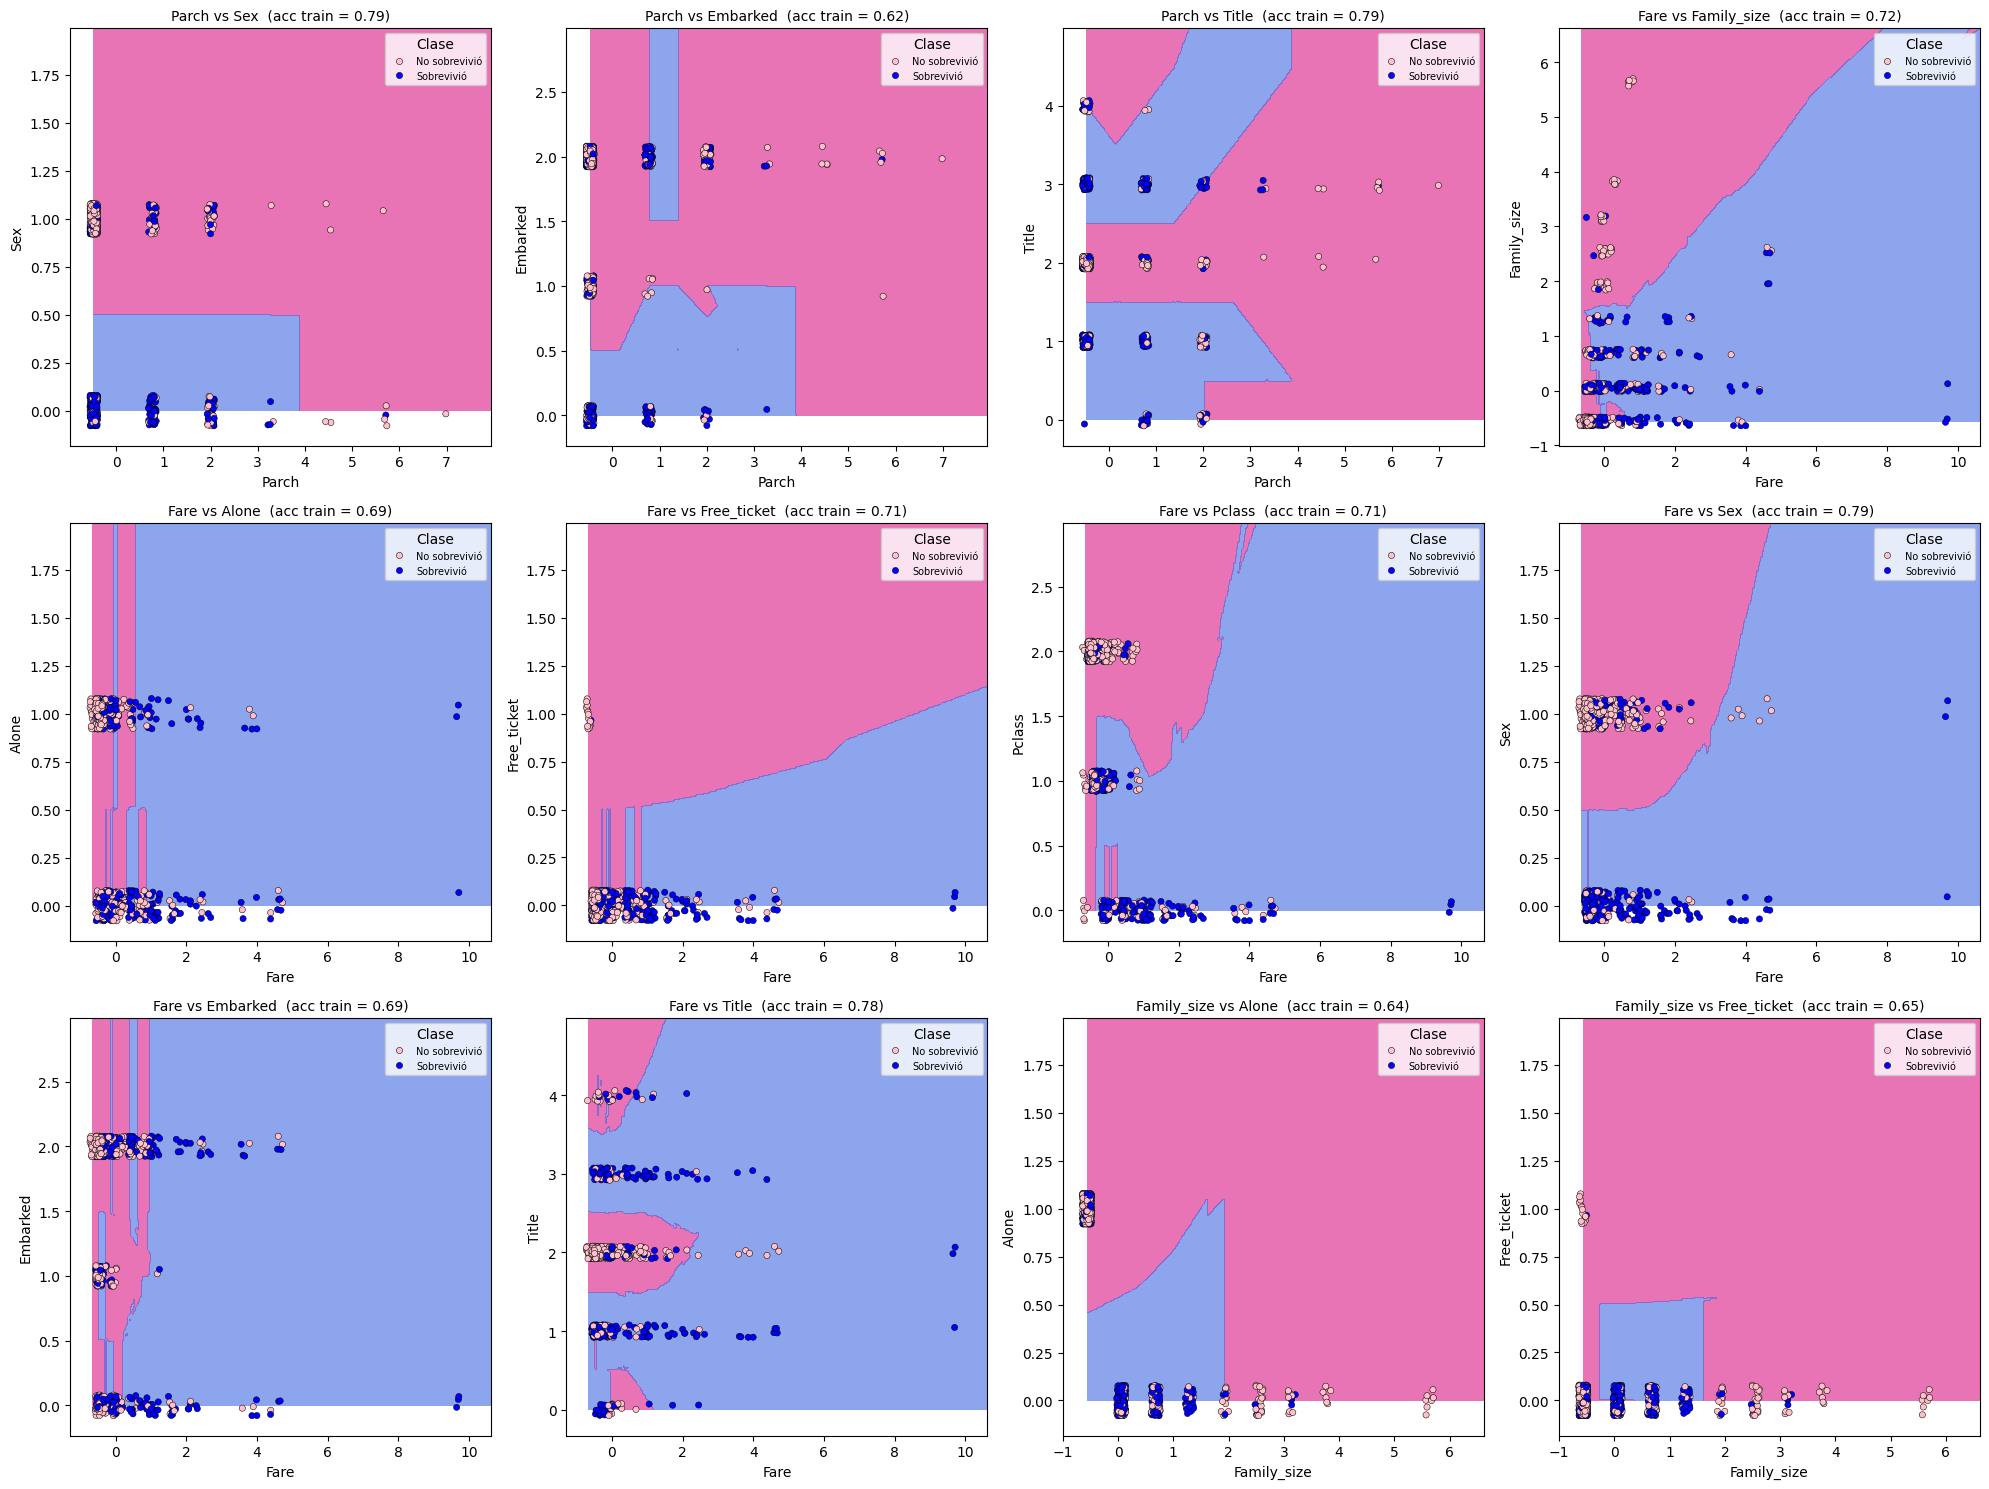

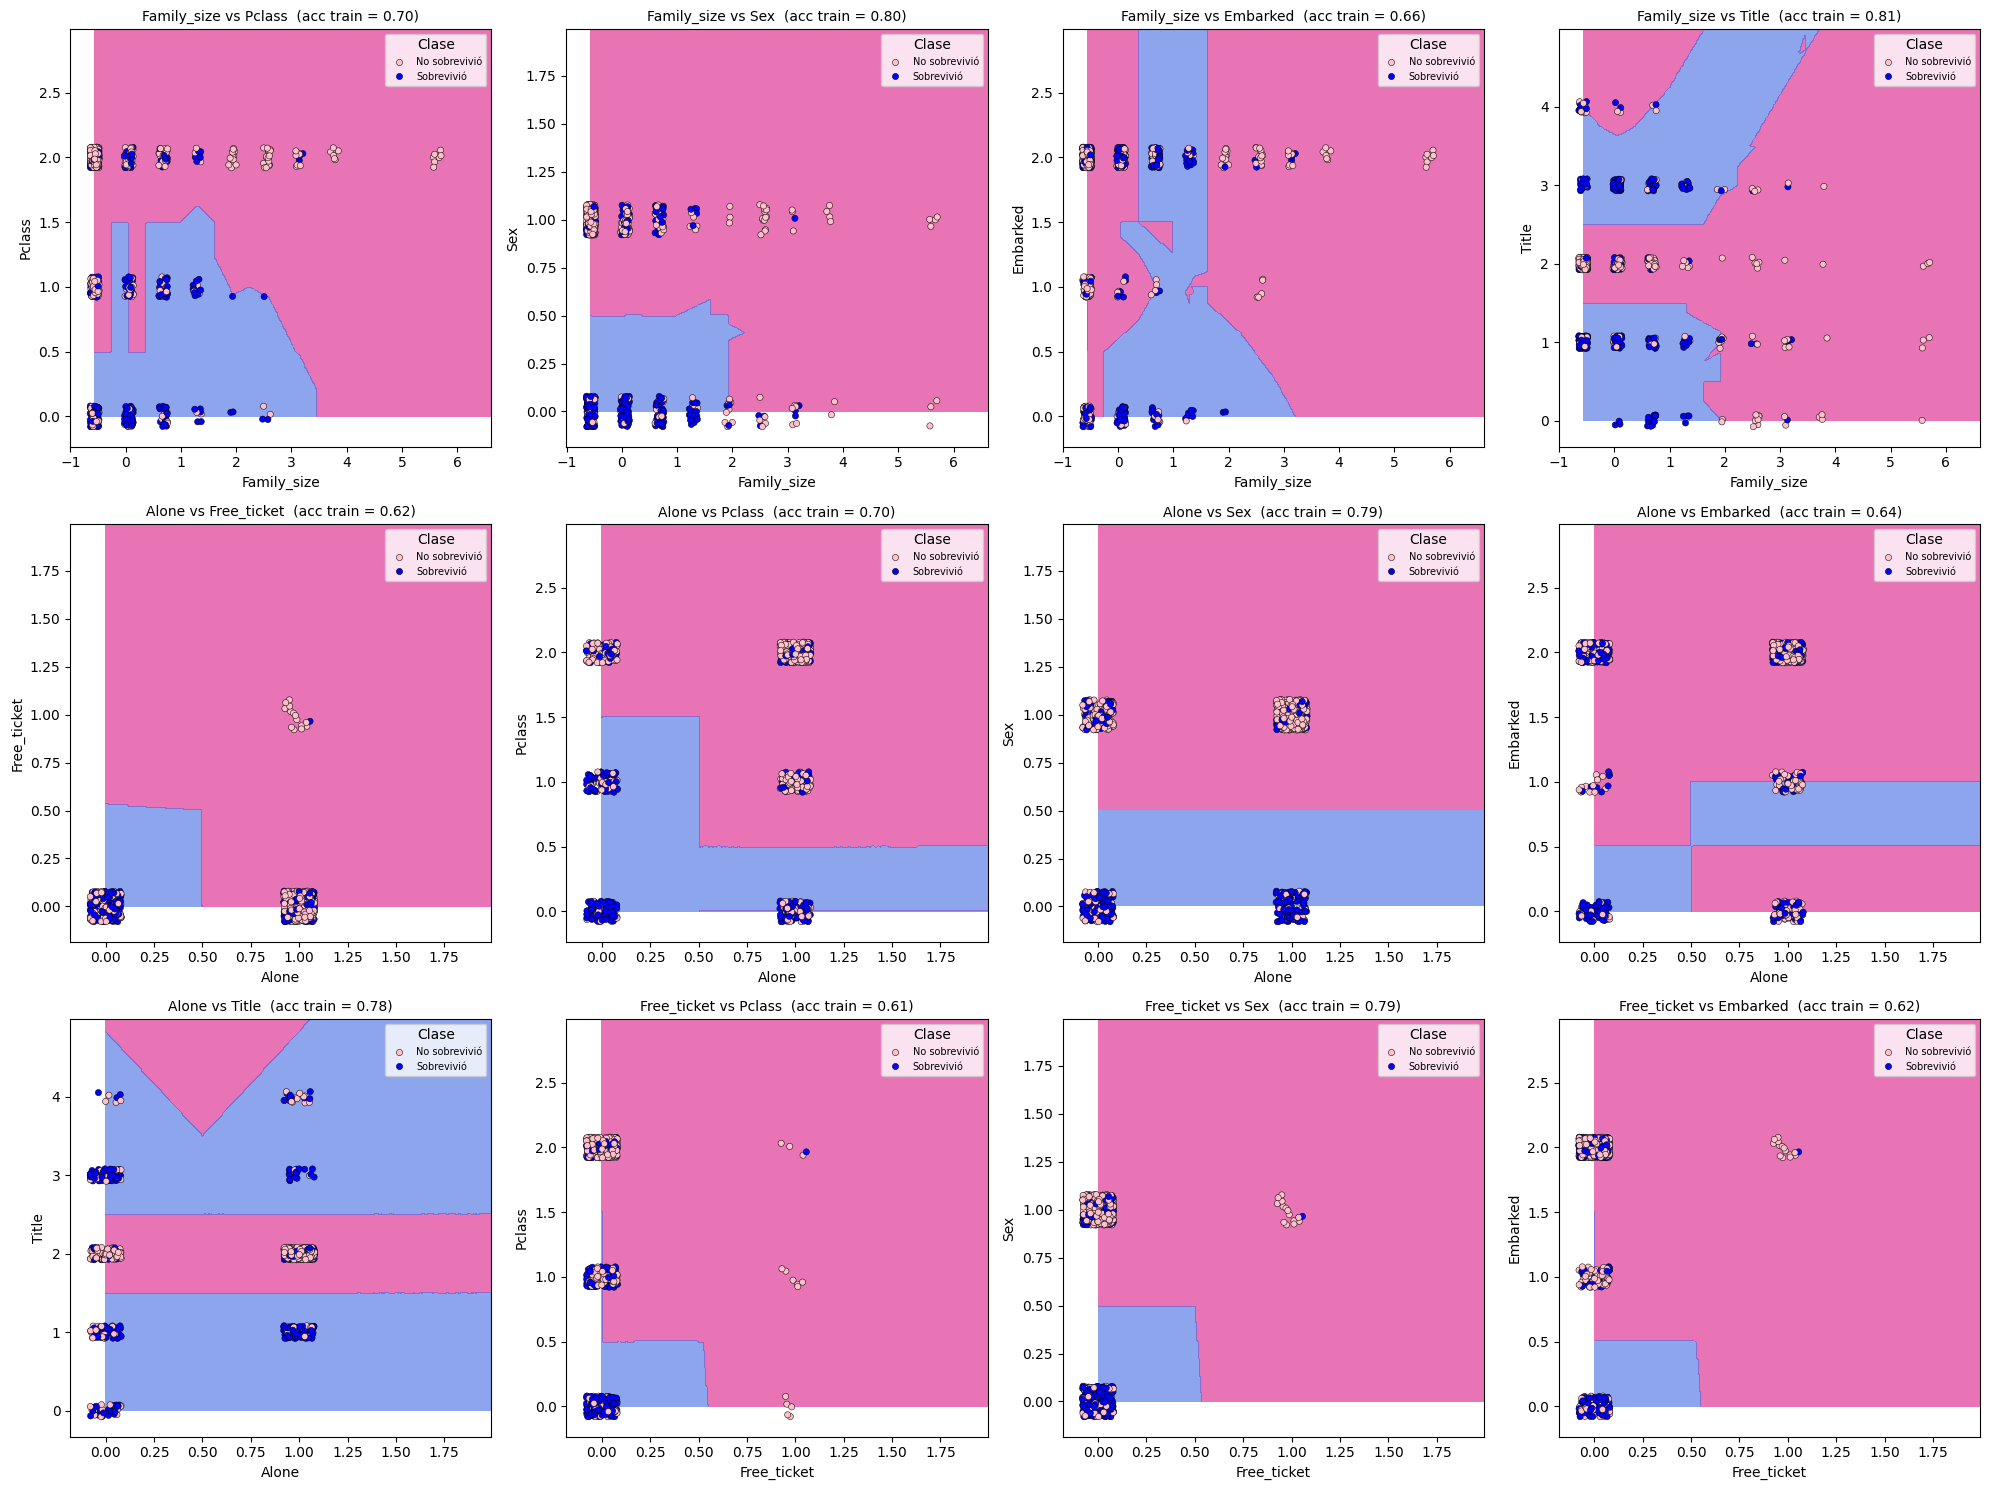

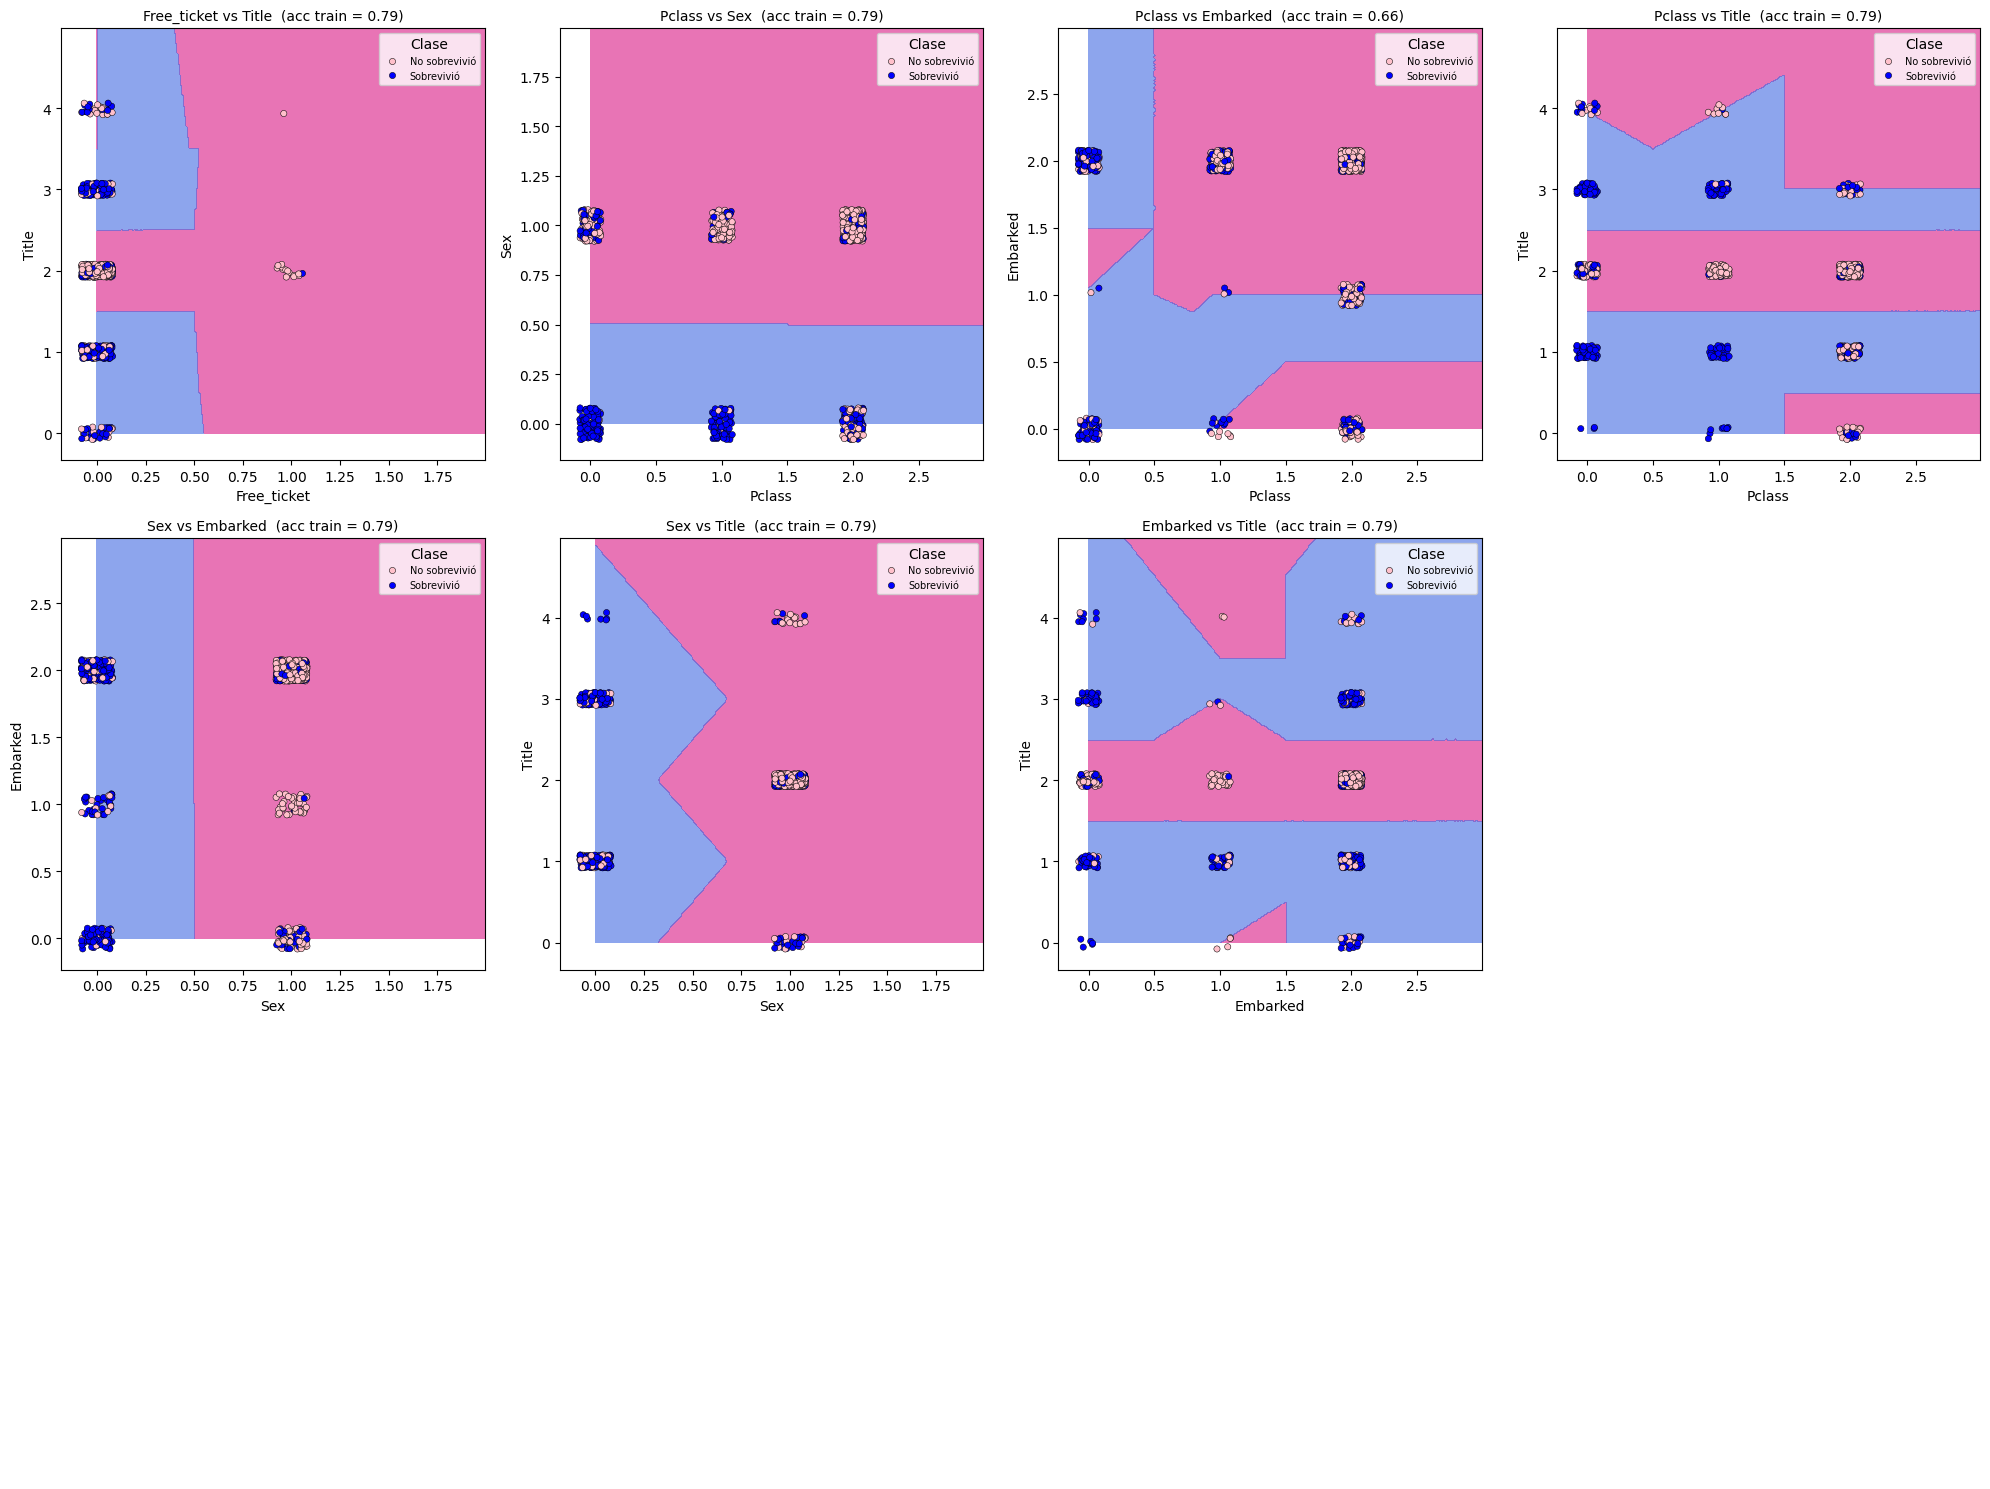

SibSp        Title    0.813692
Family_size  Title    0.811448
             Sex      0.796857
Age          Sex      0.794613
SibSp        Sex      0.793490
Parch        Sex      0.792368
Pclass       Title    0.792368
Parch        Title    0.789001
Sex          Title    0.786756
Free_ticket  Sex      0.786756
dtype: float64

In [18]:
from itertools import combinations
from sklearn.preprocessing import StandardScaler
#hiperparametros
k_vecinos = 29

pares = list(combinations(B.columns, 2))
print("Total de pares:", len(pares))  # 55

resultados = {}
for i in range(0, len(pares), 12):
    lote = pares[i:i + 12]
    fig, axes = plt.subplots(3, 4, figsize=(20, 15))
    for ax, (a, b) in zip(axes.ravel(), lote):
        resultados[(a, b)] = dibujar_par(ax, a, b)
    for ax in axes.ravel()[len(lote):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

pd.Series(resultados).sort_values(ascending=False).head(10)